# Mini Project 1: Probability, Bayes, and Discrete Random Variables

In [145]:
# Put imports here
import numpy as np
import mp1lib as ml
import scipy as sp
import matplotlib as mp
import matplotlib.pyplot as plt
import jupyter as jp

SEED = 733634
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8 = rng.spawn(8)

Matplotlib is building the font cache; this may take a moment.


## Step 1: The sample space and the axioms

C:\Users\natha\AppData\Local\Temp\ipykernel_89800\1936948883.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set(xticklabels = [f"{i:04b}" for i in range(16)],


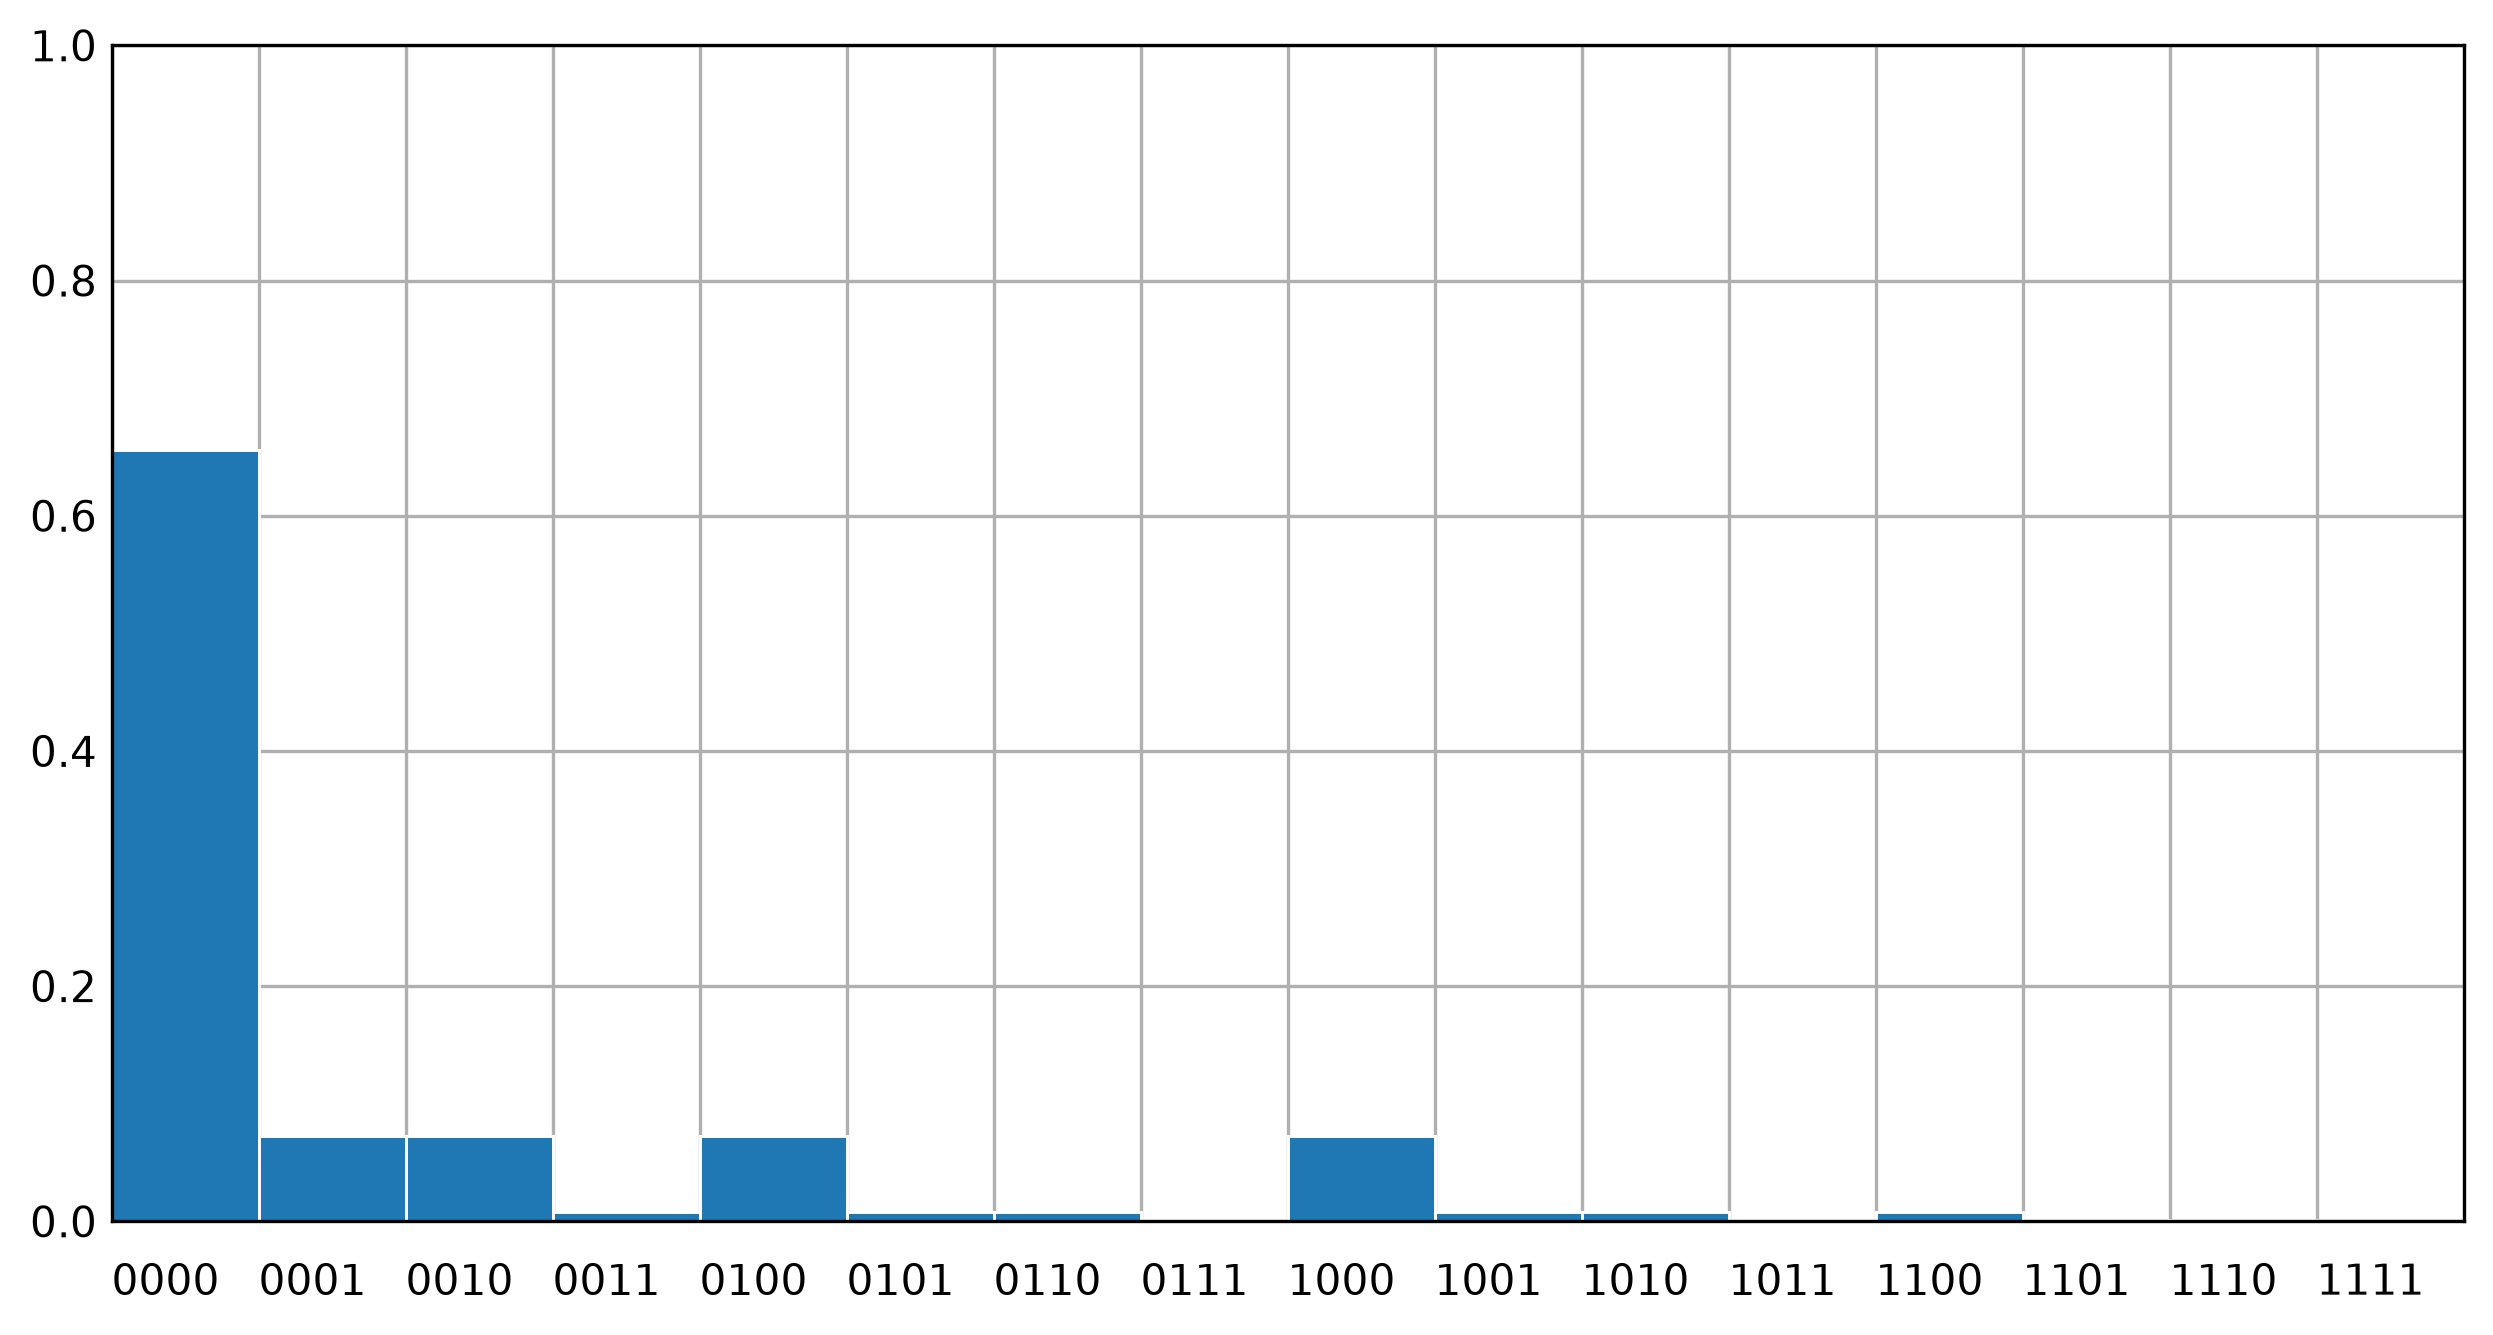

pattern 0000: p = 0.6561
pattern 0001: p = 0.0729
pattern 0010: p = 0.0729
pattern 0011: p = 0.0081
pattern 0100: p = 0.0729
pattern 0101: p = 0.0081
pattern 0110: p = 0.0081
pattern 0111: p = 0.0009
pattern 1000: p = 0.0729
pattern 1001: p = 0.0081
pattern 1010: p = 0.0081
pattern 1011: p = 0.0009
pattern 1100: p = 0.0081
pattern 1101: p = 0.0009
pattern 1110: p = 0.0009
pattern 1111: p = 0.0001

sum = 1.0000


In [181]:
# Question 1

n_bits, p = 4, 0.1
pattern = np.zeros(16) # pattern[#] = binary packet value with err = 1 and ~err=0

def err_pattern(n_bits, p, n_errs):
    return (1 - p) ** (n_bits - n_errs) * p ** n_errs

for i in range(16):
    pattern[i] = err_pattern(n_bits, p, i.bit_count())


plt.style.use('_mpl-gallery')

# make data:
x = 0.5 + np.arange(16)
y = pattern

# plot
fig, ax = plt.subplots(figsize=(8,4), dpi=300)

ax.bar(x, y, width=1, edgecolor="white", linewidth=0.7)

ax.set(xticklabels = [f"{i:04b}" for i in range(16)],
       xlim = (0, 16), xticks = np.arange(16),
       ylim = (0, 1), yticks = np.arange(0, 1.1, 0.2))

ax.tick_params(axis='x', pad=10) # Push text down slightly to clear the grid line
for label in ax.get_xticklabels():
    label.set_horizontalalignment('left')

plt.show()

for i in range(16):
    print(f"pattern {i:04b}: p = {pattern[i]:.4f}")
print(f"\nsum = {np.sum(pattern):.4f}")

In [101]:
# Question 2

P_A = 1 - sp.stats.binom.pmf(0, 2, p)
P_B = sp.stats.binom.pmf(2, n_bits, p)
P_C = p

print("Theoretical:")
print(f"P(A) = {P_A:.4f}")
print(f"P(B) = {P_B:.4f}")
print(f"P(B) = {P_C:.4f}")

Theoretical:
P(A) = 0.1900
P(B) = 0.0486
P(B) = 0.1000


In [102]:
# Question 3

N = 10 ** 6

P_A_sim = np.sum(ml.packet_errors(N, 2, p, rng_1) > 0) / N
P_B_sim = np.sum(ml.packet_errors(N, n_bits, p, rng_1) == 2) / N
P_C_sim = np.sum(ml.packet_errors(N, 1, p, rng_1)) / N

print("Simulation:")
print(f"P(A) \u2248 {P_A_sim:.4f}")
print(f"P(B) \u2248 {P_B_sim:.4f}")
print(f"P(C) \u2248 {P_C_sim:.4f}")

Simulation:
P(A) ≈ 0.1899
P(B) ≈ 0.0480
P(C) ≈ 0.0997


In [103]:
# Question 4

P_AB = P_B - P_B / sp.special.comb(4, 2)
P_BC = p * sp.stats.binom.pmf(1, n_bits-1, p)
P_CA = P_C * P_A
P_ABC = sp.stats.binom.pmf(1, 2, p) * (1-p) * p

bits_in = np.zeros((N,n_bits), int)
bits_out = ml.bsc(bits_in, p, rng_1)
A_arr_err = np.sum(bits_out[:, :2], axis = 1) > 0
B_arr_err = np.sum(bits_out, axis = 1) == 2
C_arr_err = bits_out[:, 3]

P_AB_sim = np.sum(A_arr_err & B_arr_err) / N
P_BC_sim = np.sum(B_arr_err & C_arr_err) / N
P_CA_sim = np.sum(C_arr_err & A_arr_err) / N
P_ABC_sim = np.sum(A_arr_err & B_arr_err & C_arr_err) / N

print("Theoretical:")
print(f"P(A \u2229 B) = {P_AB:.4f}")
print(f"P(B \u2229 C) = {P_BC:.4f}")
print(f"P(C \u2229 A) = {P_CA:.4f}")
print(f"P(A \u2229 B \u2229 C) = {P_ABC:.4f}\n")

print("Simulation:")
print(f"P(A \u2229 B) \u2248 {P_AB_sim:.4f}")
print(f"P(B \u2229 C) \u2248 {P_BC_sim:.4f}")
print(f"P(C \u2229 A) \u2248 {P_CA_sim:.4f}")
print(f"P(A \u2229 B \u2229 C) \u2248 {P_ABC_sim:.4f}")

Theoretical:
P(A ∩ B) = 0.0405
P(B ∩ C) = 0.0243
P(C ∩ A) = 0.0190
P(A ∩ B ∩ C) = 0.0162

Simulation:
P(A ∩ B) ≈ 0.0405
P(B ∩ C) ≈ 0.0241
P(C ∩ A) ≈ 0.0190
P(A ∩ B ∩ C) ≈ 0.0162


In [ ]:
# Question 5

P_ABCU = 1 - sp.stats.binom.pmf(0, 3, p)
P_ABCU_IE = P_A + P_B + P_C - P_AB - P_BC - P_CA + P_ABC

P_ABCU_sim = np.sum(A_arr_err | B_arr_err | C_arr_err) / N
P_ABCU_sim_IE = P_A_sim + P_B_sim + P_C_sim - P_AB_sim - P_BC_sim - P_CA_sim + P_ABC_sim

print("Theoretical:")
print(f"w/o IE formula: P(A \u222A B \u222A C) = {P_ABCU:.4f}")
print(f"w/  IE formula: P(A \u222A B \u222A C) = {P_ABCU_IE:.4f}\n")

print("Simulation:")
print(f"w/o IE formula: P(A \u222A B \u222A C) \u2248 {P_ABCU_sim:.4f}")
print(f"w/  IE formula: P(A \u222A B \u222A C) \u2248 {P_ABCU_sim_IE:.4f}")

Theoretical:
w/o IE formula: P(A ∪ B ∪ C) = 0.2710
w/  IE formula: P(A ∪ B ∪ C) = 0.2710

Simulation:
w/o IE formula: P(A ∪ B ∪ C) ≈ 0.2712
w/  IE formula: P(A ∪ B ∪ C) ≈ 0.2703


In [141]:
# Question 6

results = [
    (P_A, P_A_sim, "Event A"),
    (P_B, P_B_sim, "Event B"),
    (P_C, P_C_sim, "Event C"),
    (P_AB, P_AB_sim, "Intersect AB"),
    (P_BC, P_BC_sim, "Intersect BC"),
    (P_CA, P_CA_sim, "Intersect CA"),
    (P_ABC, P_ABC_sim, "Intersect ABC"),
    (P_ABCU, P_ABCU_sim, "Union ABC"),
    (P_ABCU_IE, P_ABCU_sim_IE, "Union ABC IE")
]

print(f"{'Event':<16} | {'Simulated':<11} | {'Theoretical':<11} | {'Difference':<11} | {'Std. Error':<11} | <3SE")
print("-" * 80)

for p_theory, p_sim, event in results:
    SE = np.sqrt((p_theory * (1 - p_theory)) / N)
    thresh = 3 * SE
    diff = np.abs(p_sim - p_theory)
    test = diff <= thresh
    
    print(f"{event:<16} | {p_sim:<11.6f} | {p_theory:<11.6f} | {diff:<11.6f} | {SE:<11.6f} | {test}")
    
    assert test, f"{event} variation exceeds standard error parameters."

print("\nAll simulations estimate within 3 standard errors.")


Event            | Simulated   | Theoretical | Difference  | Std. Error  | <3SE
--------------------------------------------------------------------------------
Event A          | 0.189858    | 0.190000    | 0.000142    | 0.000392    | True
Event B          | 0.048042    | 0.048600    | 0.000558    | 0.000215    | True
Event C          | 0.099731    | 0.100000    | 0.000269    | 0.000300    | True
Intersect AB     | 0.040477    | 0.040500    | 0.000023    | 0.000197    | True
Intersect BC     | 0.024092    | 0.024300    | 0.000208    | 0.000154    | True
Intersect CA     | 0.018981    | 0.019000    | 0.000019    | 0.000137    | True
Intersect ABC    | 0.016183    | 0.016200    | 0.000017    | 0.000126    | True
Union ABC        | 0.271215    | 0.271000    | 0.000215    | 0.000444    | True
Union ABC IE     | 0.270264    | 0.271000    | 0.000736    | 0.000444    | True

All simulations estimate within 3 standard errors.


## Step 2: Conditional probability and Bayes

### Question 1.

$P(F|err) = 0.95$

$P(err) = p$

$P(err|F) = \frac{P(F|err)P(err)}{P(F)}$

$P(F|err^c) = 0.02$

$P(err^c) = 1-p$

$P(err^c|F) = \frac{P(F|err^c)P(err^c)}{P(F)}$

In [6]:
# call rng_2

## Step 3: Independence

In [7]:
# call rng_3

## Step 4: Bernoulli trials and the Binomial

In [8]:
# call rng_4

## Step 5: The Poisson approximation

In [9]:
# call rng_5

## Step 6: Retransmissions and the geometric distribution

In [10]:
# call rng_6

## Step 7: Expectation, variance, and how fast estimates settle

In [11]:
# call rng_7

## Step 8: Putting it together, the throughput of the link

In [12]:
# call rng_8